TIME SERIES WITH REGULARISATION

Raw data (BTC price + 12 features)
        ↓
ADF stationarity tests → transform all series to stationary
        ↓
Build feature matrix X (>10 variables) + target y
        ↓
Scale features (StandardScaler — essential before Elastic Net)
        ↓
TimeSeriesSplit CV + ElasticNetCV → optimal λ and α
        ↓
Fit final model → sparse coefficient vector
        ↓
Evaluate on hold-out test set → RMSE, MAE, R²
        ↓
Interpret surviving features economically

In [34]:
# Run once — installs yfinance if not already present
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "yfinance", "--quiet"])
print("Dependencies ready.")

Dependencies ready.


In [27]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.


In [36]:
import requests
import json
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings

from datetime import datetime, timedelta

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.6f}".format)
plt.style.use("seaborn-v0_8-whitegrid")

print("All imports successful.")
print(f"Analysis date: {datetime.today().strftime('%Y-%m-%d')}")

All imports successful.
Analysis date: 2026-04-24


In [ ]:
CRYPTOCOMPARE_API_KEY = ""  # Free key at cryptocompare.com
START_DATE  = "2019-01-01"
END_DATE    = datetime.today().strftime("%Y-%m-%d")
LIMIT_DAYS  = 2000   # CryptoCompare free tier: max 2000 daily candles per call

# Macro tickers (all from Yahoo Finance via yfinance)
MACRO_TICKERS = {
    "ETH":   "ETH-USD",    # Ethereum — crypto spillover
    "SPY":   "SPY",        # S&P 500 ETF — equity risk sentiment
    "GLD":   "GLD",        # Gold ETF — safe-haven rotation
    "DXY":   "DX-Y.NYB",   # USD Index — dollar strength
    "VIX":   "^VIX",       # CBOE Volatility Index — fear gauge
    "TNX":   "^TNX",       # US 10-Year Treasury Yield
}

print(f"Date range: {START_DATE} → {END_DATE}")
print(f"Macro series to collect: {list(MACRO_TICKERS.keys())}")

Date range: 2019-01-01 → 2026-04-24
Macro series to collect: ['ETH', 'SPY', 'GLD', 'DXY', 'VIX', 'TNX']


In [38]:
def fetch_btc_cryptocompare(api_key: str, limit: int = 2000) -> pd.DataFrame:
    """
    Pull BTC/USD daily OHLCV from CryptoCompare.
    Mirrors the professor's loop pattern: requests → json → json_normalize → datetime index.
    """
    url = (
        "https://min-api.cryptocompare.com/data/v2/histoday"
        f"?fsym=BTC&tsym=USD&limit={limit}&api_key={api_key}"
    )

    response  = requests.get(url)
    json_data = response.json()

    if json_data.get("Response") != "Success":
        raise ValueError(f"CryptoCompare API error: {json_data.get('Message')}")

    # Flatten nested JSON → DataFrame (pd.json_normalize as in the slides)
    table = pd.json_normalize(json_data["Data"]["Data"])
    table["time"] = pd.to_datetime(table["time"], unit="s")
    table = table.set_index("time")
    table.index.name = "date"

    # Keep close and volume only
    btc = table[["close", "volumefrom"]].copy()
    btc.columns = ["BTC_close", "BTC_volume"]
    btc = btc[btc["BTC_close"] > 0]   # drop any zero-price rows

    return btc


btc_raw = fetch_btc_cryptocompare(CRYPTOCOMPARE_API_KEY, limit=LIMIT_DAYS)

print(f"BTC data shape : {btc_raw.shape}")
print(f"Date range     : {btc_raw.index[0].date()} → {btc_raw.index[-1].date()}")
btc_raw.tail(5)

BTC data shape : (2001, 2)
Date range     : 2020-11-01 → 2026-04-24


,BTC_close,BTC_volume
date,,
2026-04-20,75864.880000,23467.240000
2026-04-21,76349.350000,23009.240000
2026-04-22,78209.430000,30196.530000
2026-04-23,78283.640000,26275.530000
2026-04-24,78397.550000,183.620000


In [ ]:
#Fetch the macro data from Yahoo Finance using yfinance. This function loops through the tickers, downloads the data, and concatenates it into a single DataFrame aligned to BTC dates.
def fetch_macro_yfinance(tickers: dict, start: str, end: str) -> pd.DataFrame:
    """
    Download daily adjusted close for each macro ticker via yfinance.
    Returns a wide DataFrame aligned to BTC dates.
    """
    frames = {}
    for label, ticker in tickers.items():
        print(f"  Downloading {label} ({ticker})...", end=" ")
        try:
            raw = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
            # yfinance returns MultiIndex columns when single ticker — flatten
            if isinstance(raw.columns, pd.MultiIndex):
                raw.columns = raw.columns.get_level_values(0)
            frames[label] = raw["Close"].rename(label)
            print(f"✓  {len(raw)} rows")
        except Exception as e:
            print(f"✗  {e}")

    macro_df = pd.concat(frames, axis=1)
    macro_df.index = pd.to_datetime(macro_df.index)
    macro_df.index.name = "date"
    return macro_df


print("Fetching macro data from Yahoo Finance...")
macro_raw = fetch_macro_yfinance(MACRO_TICKERS, start=START_DATE, end=END_DATE)

print(f"\nMacro data shape: {macro_raw.shape}")
macro_raw.tail(5)

Fetching macro data from Yahoo Finance...

Macro data shape: (2670, 6)


,ETH,SPY,GLD,DXY,VIX,TNX
date,,,,,,
2026-04-19,2264.916992,NaN,NaN,NaN,NaN,NaN
2026-04-20,2315.212402,708.719971,442.089996,98.050003,18.870001,4.250000
2026-04-21,2327.970459,704.080017,429.570007,98.410004,19.500000,4.292000
2026-04-22,2376.088135,711.210022,435.260010,98.589996,18.920000,4.294000
2026-04-23,NaN,708.450012,431.040009,98.814003,19.309999,4.323000


In [40]:
# Align both DataFrames on the same date index (inner join = only dates where ALL exist)
df = btc_raw.join(macro_raw, how="inner")
df = df.sort_index()
df = df.dropna()

print(f"Merged dataset shape : {df.shape}")
print(f"Date range           : {df.index[0].date()} → {df.index[-1].date()}")
print(f"\nColumns:\n{df.columns.tolist()}")
df.head(3)

Merged dataset shape : (1373, 8)
Date range           : 2020-11-02 → 2026-04-22

Columns:
['BTC_close', 'BTC_volume', 'ETH', 'SPY', 'GLD', 'DXY', 'VIX', 'TNX']


,BTC_close,BTC_volume,ETH,SPY,GLD,DXY,VIX,TNX
date,,,,,,,,
2020-11-02,13571.240000,33465.170000,383.156738,306.089630,177.910004,94.050003,37.130001,0.849000
2020-11-03,14023.780000,21969.700000,387.602173,311.493958,178.919998,93.550003,35.549999,0.882000
2020-11-04,14157.730000,30406.020000,402.141998,318.455627,178.820007,93.410004,29.570000,0.768000


In [ ]:
#Log returns for price series 
#r_t = ln(P_t / P_{t-1}) converts non-stationary prices to stationary returns
price_cols = ["BTC_close", "ETH", "SPY", "GLD", "DXY"]

returns = np.log(df[price_cols] / df[price_cols].shift(1))
returns.columns = [c + "_ret" for c in price_cols]

#First difference for VIX and TNX (index levels, not prices)
returns["VIX_chg"] = df["VIX"].diff()
returns["TNX_chg"] = df["TNX"].diff()

# Volume: log-difference (captures proportional volume changes)
returns["BTC_volume_chg"] = np.log(df["BTC_volume"] / df["BTC_volume"].shift(1))

# Drop the first row (NaN from differencing)
returns = returns.dropna()

print(f"Returns DataFrame shape: {returns.shape}")
print(f"\nColumn list:")
for col in returns.columns:
    print(f"  {col}")

Returns DataFrame shape: (1372, 8)

Column list:
  BTC_close_ret
  ETH_ret
  SPY_ret
  GLD_ret
  DXY_ret
  VIX_chg
  TNX_chg
  BTC_volume_chg


In [ ]:
#Lagged BTC returns: lags 1–5 
for lag in range(1, 6):
    returns[f"BTC_ret_lag{lag}"] = returns["BTC_close_ret"].shift(lag)

#Rolling 7-day realised volatility of BTC 
returns["BTC_vol7d"] = returns["BTC_close_ret"].rolling(7).std()

# Drop NaNs introduced by lags and rolling window
returns = returns.dropna()

#Define target (y) and features (X) 
TARGET = "BTC_close_ret"
FEATURES = [col for col in returns.columns if col != TARGET]

X = returns[FEATURES]
y = returns[TARGET]

print(f"Target variable : {TARGET}")
print(f"Number of features : {len(FEATURES)}  (requirement: >10 ✓)")
print(f"Feature list:")
for i, f in enumerate(FEATURES, 1):
    print(f"  {i:02d}. {f}")
print(f"\nFinal dataset: {X.shape[0]} observations × {X.shape[1]} features")

Target variable : BTC_close_ret
Number of features : 13  (requirement: >10 ✓)
Feature list:
  01. ETH_ret
  02. SPY_ret
  03. GLD_ret
  04. DXY_ret
  05. VIX_chg
  06. TNX_chg
  07. BTC_volume_chg
  08. BTC_ret_lag1
  09. BTC_ret_lag2
  10. BTC_ret_lag3
  11. BTC_ret_lag4
  12. BTC_ret_lag5
  13. BTC_vol7d

Final dataset: 1366 observations × 13 features


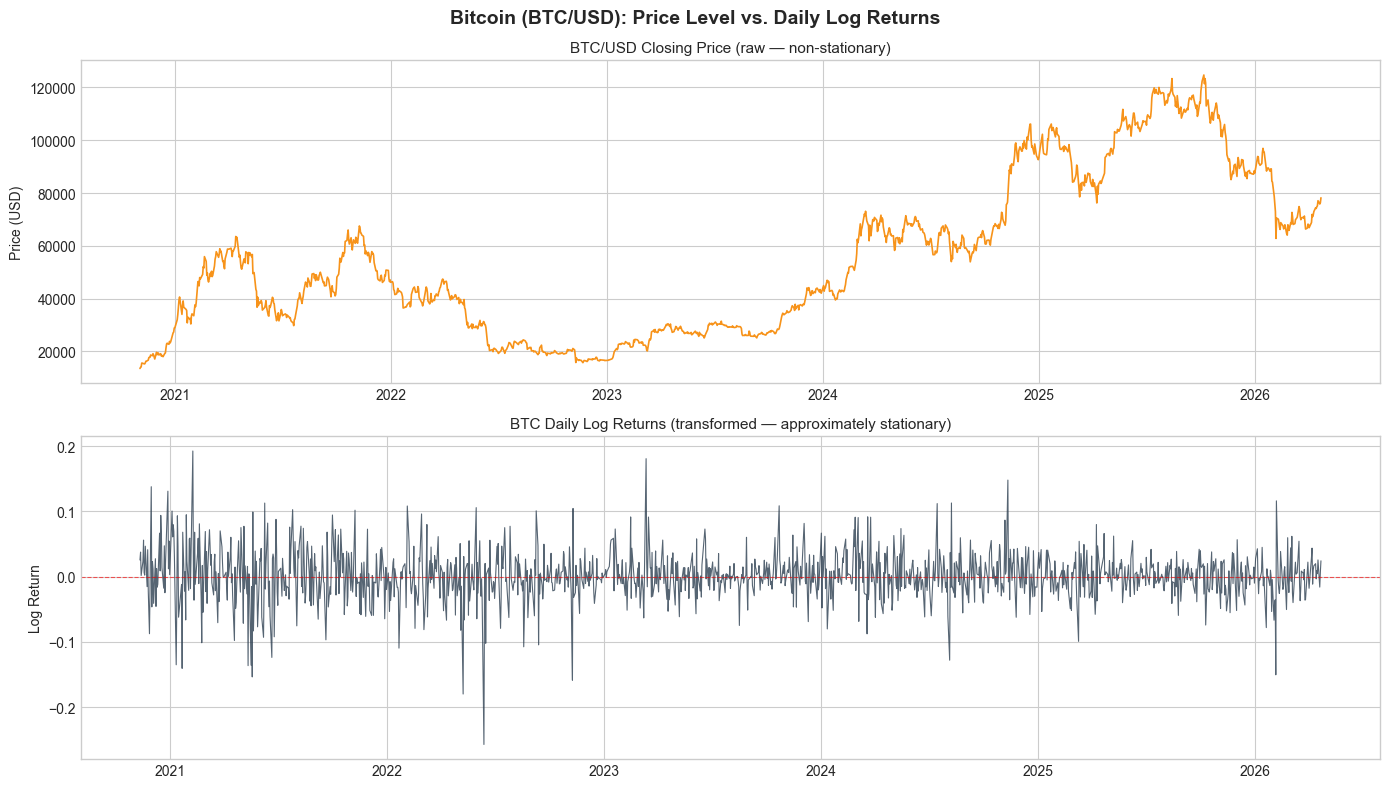

Plot saved.


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)
fig.suptitle("Bitcoin (BTC/USD): Price Level vs. Daily Log Returns", fontsize=14, fontweight="bold")

# Raw price (non-stationary)
axes[0].plot(df.index, df["BTC_close"], color="#F7931A", linewidth=1.2)
axes[0].set_title("BTC/USD Closing Price (raw — non-stationary)", fontsize=11)
axes[0].set_ylabel("Price (USD)")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# Log returns (stationary)
axes[1].plot(returns.index, returns["BTC_close_ret"], color="#2C3E50", linewidth=0.8, alpha=0.8)
axes[1].axhline(0, color="red", linestyle="--", linewidth=0.8, alpha=0.6)
axes[1].set_title("BTC Daily Log Returns (transformed — approximately stationary)", fontsize=11)
axes[1].set_ylabel("Log Return")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig("btc_price_vs_returns.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved.")

In [ ]:
# ADF test function and execution for both raw prices and log returns. The function runs the Augmented Dickey-Fuller test and formats the results into a dictionary for easy comparison.
from statsmodels.tsa.stattools import adfuller

def run_adf(series: pd.Series, name: str, maxlag: int = 10) -> dict:
    """
    Augmented Dickey-Fuller test.
    H0: series has a unit root (non-stationary).
    Reject H0 (p < 0.05) → series is stationary.
    """
    result = adfuller(series.dropna(), maxlag=maxlag, autolag="AIC")
    return {
        "Series"        : name,
        "ADF Statistic" : round(result[0], 4),
        "p-value"       : round(result[1], 4),
        "Lags Used"     : result[2],
        "Obs Used"      : result[3],
        "1% Critical"   : round(result[4]["1%"], 4),
        "5% Critical"   : round(result[4]["5%"], 4),
        "Stationary?"   : "✓ YES" if result[1] < 0.05 else "✗ NO  ← needs differencing",
    }


# Test raw prices
print("=" * 70)
print("ADF TESTS — RAW PRICE LEVELS (expect non-stationary)")
print("=" * 70)
raw_results = []
for col in price_cols:
    raw_results.append(run_adf(df[col], name=col + " (level)"))
raw_df = pd.DataFrame(raw_results).set_index("Series")
print(raw_df[["ADF Statistic", "p-value", "5% Critical", "Stationary?"]].to_string())

# Test log returns 
print("\n" + "=" * 70)
print("ADF TESTS — LOG RETURNS & DIFFERENCES (expect stationary)")
print("=" * 70)
ret_results = []
for col in returns.columns:
    ret_results.append(run_adf(returns[col], name=col))
ret_df = pd.DataFrame(ret_results).set_index("Series")
print(ret_df[["ADF Statistic", "p-value", "5% Critical", "Stationary?"]].to_string())

ADF TESTS — RAW PRICE LEVELS (expect non-stationary)
                   ADF Statistic  p-value  5% Critical                 Stationary?
Series                                                                            
BTC_close (level)      -1.475800 0.545500    -2.863700  ✗ NO  ← needs differencing
ETH (level)            -2.942000 0.040700    -2.863700                       ✓ YES
SPY (level)             0.185400 0.971400    -2.863700  ✗ NO  ← needs differencing
GLD (level)             1.850600 0.998400    -2.863700  ✗ NO  ← needs differencing
DXY (level)            -1.730000 0.415700    -2.863700  ✗ NO  ← needs differencing

ADF TESTS — LOG RETURNS & DIFFERENCES (expect stationary)
                ADF Statistic  p-value  5% Critical Stationary?
Series                                                         
BTC_close_ret      -20.236100 0.000000    -2.863700       ✓ YES
ETH_ret            -38.345700 0.000000    -2.863700       ✓ YES
SPY_ret            -23.089900 0.000000    -2.863700

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNetCV, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#Temporal train/test split — never shuffle time series
TEST_FRAC = 0.20
split_idx = int(len(X) * (1 - TEST_FRAC))

X_train_raw = X.iloc[:split_idx]
X_test_raw  = X.iloc[split_idx:]
y_train     = y.iloc[:split_idx]
y_test      = y.iloc[split_idx:]

print(f"Training set : {X_train_raw.index[0].date()} → {X_train_raw.index[-1].date()}  ({len(y_train)} obs)")
print(f"Test set     : {X_test_raw.index[0].date()}  → {X_test_raw.index[-1].date()}  ({len(y_test)} obs)")
print(f"Feature count: {X_train_raw.shape[1]}")

Training set : 2020-11-11 → 2025-03-19  (1092 obs)
Test set     : 2025-03-20  → 2026-04-22  (274 obs)
Feature count: 13


In [ ]:
#Fit scaler on trainingdata only, then apply to both sets
#Fitting on the full dataset would leak test-set statistics — data leakage.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test  = scaler.transform(X_test_raw)      # transform only — no re-fitting

print("Scaling complete.")
print(f"Train mean (should be ~0): {X_train.mean(axis=0).round(4)[:3]} ...")
print(f"Train std  (should be ~1): {X_train.std(axis=0).round(4)[:3]}  ...")
print(f"\nIMPORTANT: Scaler fitted on training set only (no data leakage into test set)")

Scaling complete.
Train mean (should be ~0): [ 0. -0. -0.] ...
Train std  (should be ~1): [1. 1. 1.]  ...

IMPORTANT: Scaler fitted on training set only (no data leakage into test set)


In [ ]:
#TimeSeriesSplit: 5 expanding folds
# Each fold trains on all past data and validates on the immediate future window.
# This is the ONLY correct CV strategy for time series — no random shuffling.
tscv = TimeSeriesSplit(n_splits=5)

#ElasticNetCV hyperparameter grid 
# alpha  (λ in many documents) : overall regularisation strength
# l1_ratio (ρ in lectures): mix between L1 (lasso) and L2 (ridge)
# l1_ratio = 1.0 → pure Lasso (maximum sparsity)
# l1_ratio = 0.0 → pure Ridge (no variable selection)
# values in between → Elastic Net (sparsity + stability)
# Define a grid of candidate L1/L2 mixes for Elastic Net; ElasticNetCV will try each

# l1_ratio (from mostly L2 = 0.1 to pure L1 = 1.0) and let time-series CV pick the best.
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0]

elastic_net_cv = ElasticNetCV(
    l1_ratio    = l1_ratios,
    alphas      = None,        # sklearn auto-generates a sensible alpha path
    cv          = tscv,        # TimeSeriesSplit — respects temporal order
    max_iter    = 10000,
    n_jobs      = -1,          # use all CPU cores
    random_state= 42
)

elastic_net_cv.fit(X_train, y_train)

print("═" * 55)
print("  ElasticNetCV — Optimal Hyperparameters")
print("═" * 55)
print(f"  Best alpha (λ)    : {elastic_net_cv.alpha_:.6f}")
print(f"  Best l1_ratio (ρ) : {elastic_net_cv.l1_ratio_:.2f}")
print()

if elastic_net_cv.l1_ratio_ == 1.0:
    print("  → Pure Lasso selected: maximum sparsity, aggressive variable selection")
elif elastic_net_cv.l1_ratio_ >= 0.7:
    print("  → Lasso-dominant Elastic Net: strong variable selection with some L2 stability")
elif elastic_net_cv.l1_ratio_ >= 0.4:
    print("  → Balanced Elastic Net: variable selection + grouped shrinkage")
else:
    print("  → Ridge-dominant Elastic Net: strong shrinkage, moderate selection")

═══════════════════════════════════════════════════════
  ElasticNetCV — Optimal Hyperparameters
═══════════════════════════════════════════════════════
  Best alpha (λ)    : 0.001206
  Best l1_ratio (ρ) : 1.00

  → Pure Lasso selected: maximum sparsity, aggressive variable selection


In [ ]:
#Extract coefficients and identify surviving (non-zero) features 
coef_df = pd.DataFrame({
    "Feature"    : FEATURES,
    "Coefficient": elastic_net_cv.coef_
}).sort_values("Coefficient", key=abs, ascending=False)

coef_df["Survived"] = coef_df["Coefficient"].abs() > 0

surviving = coef_df[coef_df["Survived"]]
zeroed    = coef_df[~coef_df["Survived"]]

print(f"Features entering the model : {len(FEATURES)}")
print(f"Features surviving (≠ 0)    : {len(surviving)}")
print(f"Features zeroed out         : {len(zeroed)}")

print("\n── Surviving features (ordered by |coefficient|) ──")
print(surviving[["Feature", "Coefficient"]].to_string(index=False))

if len(zeroed) > 0:
    print("\n── Zeroed out by regularisation ──")
    print(zeroed[["Feature", "Coefficient"]].to_string(index=False))

Features entering the model : 13
Features surviving (≠ 0)    : 4
Features zeroed out         : 9

── Surviving features (ordered by |coefficient|) ──
       Feature  Coefficient
       ETH_ret     0.030046
       SPY_ret     0.002049
BTC_volume_chg     0.000715
       VIX_chg    -0.000696

── Zeroed out by regularisation ──
     Feature  Coefficient
     GLD_ret    -0.000000
     DXY_ret    -0.000000
     TNX_chg     0.000000
BTC_ret_lag1    -0.000000
BTC_ret_lag2    -0.000000
BTC_ret_lag3     0.000000
BTC_ret_lag4     0.000000
BTC_ret_lag5     0.000000
   BTC_vol7d     0.000000


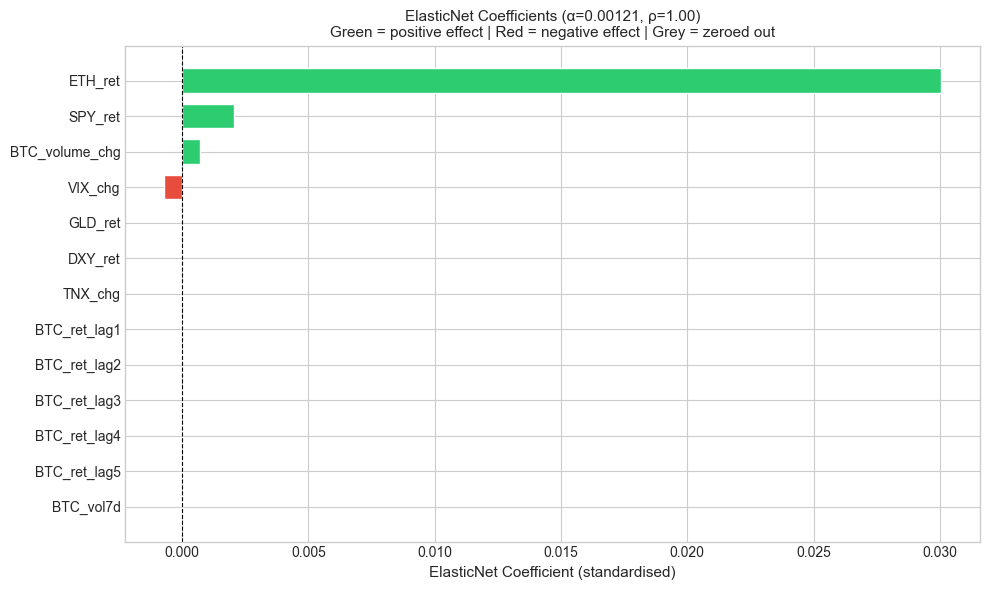

Coefficient plot saved.


In [ ]:
#Coefficient plot: green = positive effect, red = negative effect, grey = zeroed out

fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#2ECC71" if v > 0 else "#E74C3C" for v in coef_df["Coefficient"]]
# Grey out zeroed features
colors = ["#BDC3C7" if c == 0 else col for c, col in zip(coef_df["Coefficient"], colors)]

bars = ax.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors, edgecolor="white", height=0.7)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("ElasticNet Coefficient (standardised)", fontsize=11)
ax.set_title(
    f"ElasticNet Coefficients (α={elastic_net_cv.alpha_:.5f}, ρ={elastic_net_cv.l1_ratio_:.2f})\n"
    f"Green = positive effect | Red = negative effect | Grey = zeroed out",
    fontsize=11
)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("elasticnet_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()
print("Coefficient plot saved.")

In [ ]:
# Predict on training and test sets, then evaluate with RMSE, MAE, and R². The evaluation function computes these metrics and prints them in a formatted way for both in-sample (training) and 
# out-of-sample predictions.
y_pred_train = elastic_net_cv.predict(X_train)
y_pred_test  = elastic_net_cv.predict(X_test)

def eval_metrics(y_true, y_pred, label):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f"  {label:12s} | RMSE: {rmse:.6f} | MAE: {mae:.6f} | R²: {r2:.4f}")

print("═" * 60)
print("  ElasticNet Model Performance")
print("═" * 60)
eval_metrics(y_train, y_pred_train, "In-sample")
eval_metrics(y_test,  y_pred_test,  "Out-of-sample")
print()
print("  Note: Low R² is expected for daily crypto returns — financial")
print("  markets are close to efficient. The key is that out-of-sample")
print("  RMSE ≈ in-sample RMSE (no severe overfitting).")

════════════════════════════════════════════════════════════
  ElasticNet Model Performance
════════════════════════════════════════════════════════════
  In-sample    | RMSE: 0.023081 | MAE: 0.015750 | R²: 0.6608
  Out-of-sample | RMSE: 0.014460 | MAE: 0.010607 | R²: 0.7205

  Note: Low R² is expected for daily crypto returns — financial
  markets are close to efficient. The key is that out-of-sample
  RMSE ≈ in-sample RMSE (no severe overfitting).


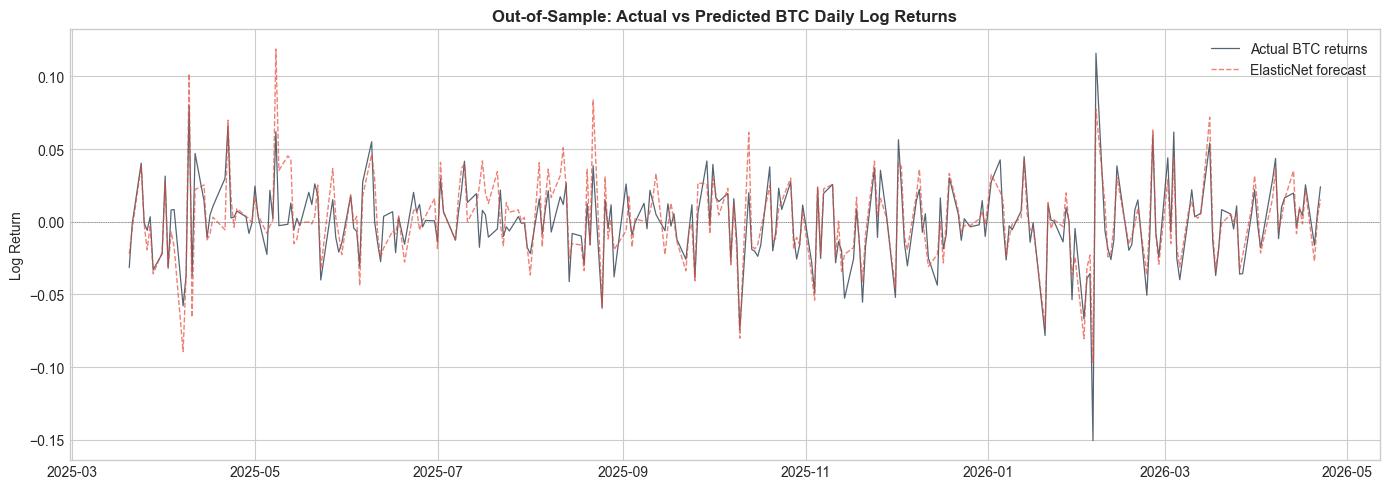

Forecast plot saved.


In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(y_test.index, y_test.values,  color="#2C3E50", linewidth=0.9, alpha=0.8, label="Actual BTC returns")
ax.plot(y_test.index, y_pred_test,    color="#E74C3C", linewidth=1.0, alpha=0.7, label="ElasticNet forecast", linestyle="--")
ax.axhline(0, color="grey", linewidth=0.6, linestyle=":")
ax.set_title("Out-of-Sample: Actual vs Predicted BTC Daily Log Returns", fontsize=12, fontweight="bold")
ax.set_ylabel("Log Return")
ax.legend(fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()
print("Forecast plot saved.")